# From RC circuit to spike

**Question:** How does a neuron turn an input current into a train of spikes, and how does its firing rate depend on the current?

**Model (leaky integrate-and-fire, LIF):** the cell membrane is an RC circuit with a battery $u_\mathrm{rest}$ (Gerstner et al., *Neuronal Dynamics*, 2014, Sect. 1.3):

$$\tau_m \frac{du}{dt} = -\,[u(t) - u_\mathrm{rest}] + R\,I(t) \qquad (1.5)$$

When $u$ reaches the threshold $\vartheta$, the neuron fires a spike and $u$ is reset to $u_r$ (Eqs. 1.12, 1.13).

Imports and plot style: numpy for the arrays, matplotlib for the figures, which are saved to `figures/`.

In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

# Plot style: quiet axes, one blue for the data
plt.rcParams.update({
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
})
BLUE = "#2a78d6"  # data
GRAY = "#52514e"  # reference lines and labels
ORANGE = "#eb6834"  # further series, in this order
AQUA = "#1baf7a"
YELLOW = "#eda100"

FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

Parameters of the LIF neuron. The units are chosen so that they fit together without conversion: MΩ · nA = mV.

In [2]:
# Units: mV, ms, MOhm, nA
u_rest = -70.0   # resting potential (mV)
theta = -50.0    # firing threshold (mV)
u_reset = -70.0  # value u jumps to after a spike (mV); here = u_rest, as in Fig. 1.9
R = 10.0         # membrane resistance (MOhm)
tau_m = 10.0     # membrane time constant tau_m = R * C (ms)

Simulation with the Euler method: in each small time step `dt`, $u$ changes by `dt` times $du/dt$ from Eq. (1.5); when $u$ reaches the threshold, the spike time is stored and $u$ is reset.

In [3]:
def simulate_lif(I, T=100.0, dt=0.1):
    """Leaky integrate-and-fire neuron with constant input current.

    I  : input current (nA)
    T  : simulated time (ms)
    dt : time step (ms)
    Returns time t (ms), membrane potential u (mV), spike times (ms).
    """
    n_steps = int(round(T / dt))
    t = np.arange(n_steps) * dt
    u = np.empty(n_steps)
    u[0] = u_rest
    spike_times = []

    for k in range(n_steps - 1):
        du = ((-(u[k] - u_rest) + R * I) / tau_m) * dt    # Euler step of Eq. (1.5)
        u[k + 1] = u[k] + du

        if u[k + 1] >= theta:           # threshold reached, Eq. (1.12)
            spike_times.append(t[k + 1])
            u[k + 1] = u_reset          # reset, Eq. (1.13)

    return t, u, np.array(spike_times)

First run: a constant current of 3 nA for 100 ms. The vertical lines only mark the spike times; the LIF model does not describe the shape of a spike (Sect. 1.3).

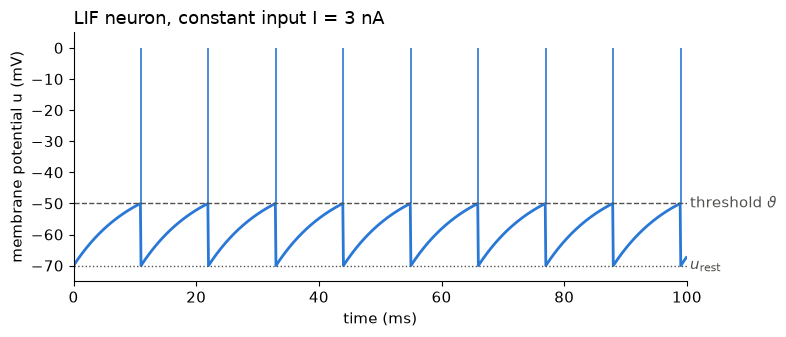

9 spikes in 100 ms


In [4]:
I = 3    # input current (nA)
T = 100.0  # simulated time (ms)
t, u, spike_times = simulate_lif(I, T)

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(t, u, color=BLUE, lw=2)
ax.vlines(spike_times, theta, 0, color=BLUE, lw=1.2)  # spike times
ax.axhline(theta, color=GRAY, lw=1, ls="--")
ax.axhline(u_rest, color=GRAY, lw=1, ls=":")
ax.text(T + 0.5, theta, r"threshold $\vartheta$", va="center", color=GRAY)
ax.text(T + 0.5, u_rest, r"$u_\mathrm{rest}$", va="center", color=GRAY)
ax.set(xlim=(0, T), ylim=(-75, 5),
       xlabel="time (ms)", ylabel="membrane potential u (mV)")
ax.set_title(f"LIF neuron, constant input I = {I} nA", loc="left")
fig.tight_layout()
fig.savefig(FIG_DIR / f"lif_trace_{I:g}nA.png", dpi=150)
plt.show()

print(f"{len(spike_times)} spikes in {T:.0f} ms")

Check against the analytical solution: setting $u = \vartheta$ in Eq. (1.7) gives the time from reset to threshold, $T_\mathrm{ISI} = \tau_m \ln\frac{RI}{RI - (\vartheta - u_\mathrm{rest})}$.

In [5]:
T_analytic = tau_m * np.log(R * I / (R * I - (theta - u_rest)))
T_sim = np.diff(spike_times).mean()
print(f"interspike interval: simulation {T_sim:.2f} ms, analytic {T_analytic:.2f} ms")

interspike interval: simulation 11.00 ms, analytic 10.99 ms


## f-I curve

For each constant current, simulate 1 s and count the spikes: the firing rate $f$ is the number of spikes per second (Hz). Below the rheobase $I_\mathrm{rh} = (\vartheta - u_\mathrm{rest})/R$ the voltage never reaches the threshold, so $f = 0$.

In [6]:
currents = np.linspace(0, 5, 51)  # input currents (nA)
T_long = 1000.0                   # 1 s of simulated time (ms)

rates_sim = []
for current in currents:
    _, _, spikes = simulate_lif(current, T_long)
    rates_sim.append(len(spikes) / (T_long / 1000))  # spikes per second (Hz)
rates_sim = np.array(rates_sim)

The analytical rate is the inverse of the interspike interval from above, $f = 1/T_\mathrm{ISI}$ (valid here because $u_r = u_\mathrm{rest}$).

In [7]:
I_rh = (theta - u_rest) / R  # rheobase (nA)


def rate_analytic(current):
    """Firing rate (Hz) of the LIF neuron for a constant current (nA)."""
    if current <= I_rh:
        return 0.0
    T_isi = tau_m * np.log(R * current / (R * current - (theta - u_rest)))  # ms
    return 1000 / T_isi


currents_fine = np.linspace(0, 5, 501)
rates_theory = [rate_analytic(c) for c in currents_fine]
print(f"rheobase: {I_rh:g} nA")

rheobase: 2 nA


Plot simulation and theory together; the dotted line marks the rheobase.

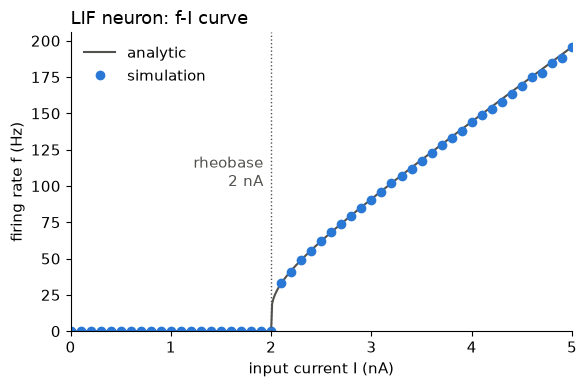

In [8]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(currents_fine, rates_theory, color=GRAY, lw=1.5, label="analytic")
ax.plot(currents, rates_sim, "o", color=BLUE, ms=6, label="simulation")
ax.axvline(I_rh, color=GRAY, lw=1, ls=":")
ax.text(I_rh - 0.08, 100, f"rheobase\n{I_rh:g} nA", ha="right", color=GRAY)
ax.set(xlim=(0, 5), ylim=(0, None),
       xlabel="input current I (nA)", ylabel="firing rate f (Hz)")
ax.set_title("LIF neuron: f-I curve", loc="left")
ax.legend(frameon=False, loc="upper left")
fig.tight_layout()
fig.savefig(FIG_DIR / "lif_fI_curve.png", dpi=150)
plt.show()

## Hodgkin-Huxley model

Same membrane capacitor, but next to the leak there are now a sodium and a potassium channel whose conductances depend on voltage and time (Sect. 2.2, Eqs. 2.4 and 2.5):

$$C\,\frac{du}{dt} = -\Big[g_\mathrm{Na}\,m^3h\,(u-E_\mathrm{Na}) + g_\mathrm{K}\,n^4\,(u-E_\mathrm{K}) + g_L\,(u-E_L)\Big] + I$$

Each gating variable $x \in \{m, h, n\}$ is the fraction of open gates and changes with voltage-dependent opening and closing rates (Eq. 2.9): $\dot{x} = \alpha_x(u)\,(1-x) - \beta_x(u)\,x$.

There is no threshold and no reset: the spikes come out of the equations. We use the original squid-axon parameters of Hodgkin and Huxley (1952), shifted so that the resting potential is −65 mV (the "original parameters" of Fig. 2.7C/D). The cortical parameters of Table 2.1 did not reproduce the jump of Fig. 2.7B in a test run.

Units: mV, ms, µF/cm², mS/cm², µA/cm² (mS · mV = µA).

In [9]:
# Original squid-axon parameters (Hodgkin & Huxley 1952), resting potential -65 mV
C_m = 1.0                 # membrane capacitance (uF/cm^2)
g_Na, E_Na = 120.0, 50.0  # sodium: max conductance (mS/cm^2), reversal potential (mV)
g_K, E_K = 36.0, -77.0    # potassium
g_L, E_L = 0.3, -54.387   # leak (E_L chosen so that the resting potential is -65 mV)


# Opening (alpha) and closing (beta) rates of the gates (1/ms), u in mV
def alpha_m(u): return 0.1 * (u + 40) / (1 - np.exp(-(u + 40) / 10))
def beta_m(u): return 4.0 * np.exp(-(u + 65) / 18)
def alpha_h(u): return 0.07 * np.exp(-(u + 65) / 20)
def beta_h(u): return 1 / (1 + np.exp(-(u + 35) / 10))
def alpha_n(u): return 0.01 * (u + 55) / (1 - np.exp(-(u + 55) / 10))
def beta_n(u): return 0.125 * np.exp(-(u + 65) / 80)

Simulation with the same Euler method as for the LIF neuron, now for four variables. The time step is ten times smaller (0.01 ms), because $m$ reacts within about 0.1–0.4 ms.

In [10]:
def simulate_hh(I, T=100.0, dt=0.01):
    """Hodgkin-Huxley neuron with constant input current.

    I  : input current (uA/cm^2)
    T  : simulated time (ms)
    dt : time step (ms)
    Returns time t (ms), membrane potential u (mV) and the gating variables m, h, n.
    """
    n_steps = int(round(T / dt))
    t = np.arange(n_steps) * dt
    u = np.empty(n_steps)
    m = np.empty(n_steps)
    h = np.empty(n_steps)
    n = np.empty(n_steps)

    # start at rest, every gate at its steady-state value x0 = alpha / (alpha + beta)
    u[0] = -65.0
    m[0] = alpha_m(u[0]) / (alpha_m(u[0]) + beta_m(u[0]))
    h[0] = alpha_h(u[0]) / (alpha_h(u[0]) + beta_h(u[0]))
    n[0] = alpha_n(u[0]) / (alpha_n(u[0]) + beta_n(u[0]))

    for k in range(n_steps - 1):
        # ionic currents: Ohm's law with a battery for each channel, Eq. (2.5)
        I_Na = g_Na * m[k]**3 * h[k] * (u[k] - E_Na)
        I_K = g_K * n[k]**4 * (u[k] - E_K)  # potassium current, Eq. (2.5)
        I_L = g_L * (u[k] - E_L)

        # Euler steps: membrane, Eq. (2.4), and gates, Eq. (2.9)
        u[k + 1] = u[k] + dt * (-(I_Na + I_K + I_L) + I) / C_m
        m[k + 1] = m[k] + dt * (alpha_m(u[k]) * (1 - m[k]) - beta_m(u[k]) * m[k])
        h[k + 1] = h[k] + dt * (alpha_h(u[k]) * (1 - h[k]) - beta_h(u[k]) * h[k])
        n[k + 1] = n[k] + dt * (alpha_n(u[k]) * (1 - n[k]) - beta_n(u[k]) * n[k])

    return t, u, m, h, n

The model has no threshold, so counting spikes needs a rule: a spike is an upward crossing of 0 mV. This is only a measuring convention, not part of the model.

In [11]:
def count_spikes(t, u, t_start=0.0):
    """Number of upward crossings of 0 mV after t_start (ms)."""
    up = (u[:-1] < 0) & (u[1:] >= 0)
    return int(np.sum(up & (t[1:] >= t_start)))

Voltage and gates for a constant current of 10 µA/cm², over 50 ms: spike shape, undershoot and the slow gates $h$ and $n$.

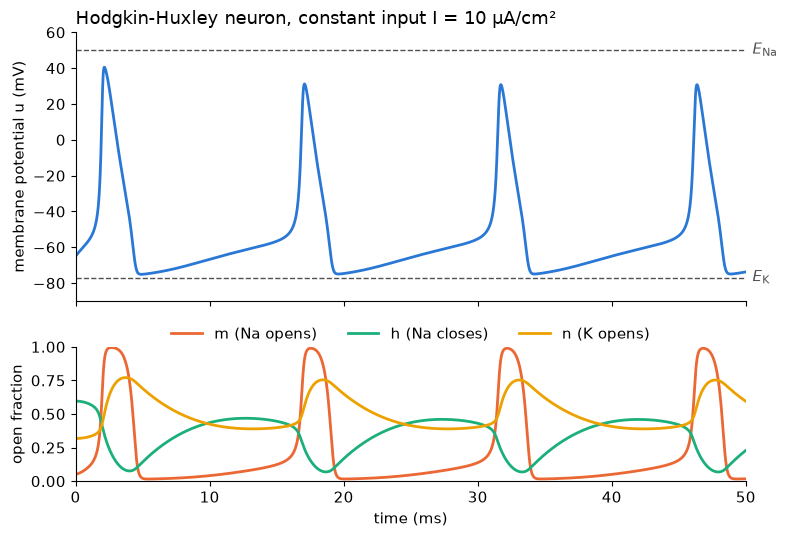

4 spikes in 50 ms; peak 40.5 mV, lowest -75.1 mV


In [12]:
I_hh = 10.0  # input current (uA/cm^2)
T_hh = 50.0  # simulated time (ms)
t, u, m, h, n = simulate_hh(I_hh, T_hh)

fig, (ax_u, ax_g) = plt.subplots(2, 1, figsize=(8, 5.5), sharex=True,
                                 gridspec_kw={"height_ratios": [2, 1]})
ax_u.plot(t, u, color=BLUE, lw=2)
for E, label in [(E_Na, r"$E_\mathrm{Na}$"), (E_K, r"$E_\mathrm{K}$")]:
    ax_u.axhline(E, color=GRAY, lw=1, ls="--")
    ax_u.text(T_hh + 0.5, E, label, va="center", color=GRAY)
ax_u.set(ylabel="membrane potential u (mV)", ylim=(-90, 60))
ax_u.set_title(f"Hodgkin-Huxley neuron, constant input I = {I_hh:g} µA/cm²", loc="left")

for x, name, color in [(m, "m (Na opens)", ORANGE), (h, "h (Na closes)", AQUA), (n, "n (K opens)", YELLOW)]:
    ax_g.plot(t, x, color=color, lw=2, label=name)
ax_g.set(xlim=(0, T_hh), ylim=(0, 1), xlabel="time (ms)", ylabel="open fraction")
ax_g.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, 1.25))
fig.tight_layout()
fig.savefig(FIG_DIR / f"hh_trace_{I_hh:g}uA.png", dpi=150)
plt.show()

print(f"{count_spikes(t, u)} spikes in {T_hh:.0f} ms; peak {u.max():.1f} mV, lowest {u.min():.1f} mV")

f-I curve of the HH neuron: 0.6 s per current; spikes in the first 0.1 s are not counted, so that a single spike at current onset does not count as firing. This cell takes about 15 seconds.

In [13]:
currents_hh = np.arange(0, 20.5, 0.5)  # input currents (uA/cm^2)
T_fI, t_skip = 600.0, 100.0           # simulated time and skipped start (ms)

rates_hh = []
for current in currents_hh:
    t_sim, u_sim, _, _, _ = simulate_hh(current, T_fI)
    n_spikes = count_spikes(t_sim, u_sim, t_start=t_skip)
    rates_hh.append(n_spikes / ((T_fI - t_skip) / 1000))  # spikes per second (Hz)
rates_hh = np.array(rates_hh)

first = np.argmax(rates_hh > 0)
print(f"no firing up to {currents_hh[first - 1]:g} µA/cm²; "
      f"at {currents_hh[first]:g} µA/cm² already {rates_hh[first]:.0f} Hz")

no firing up to 6 µA/cm²; at 6.5 µA/cm² already 56 Hz


Check of the time step: the HH model has no analytical solution, so we change `dt` and see whether the firing rates change. If halving `dt` changes nothing, `dt = 0.01` ms is small enough. (Rates are counted over 0.5 s, so they are resolved to 2 Hz.)

In [14]:
check_currents = [6.0, 6.5, 10.0, 20.0]  # input currents (uA/cm^2)
check_dts = [0.02, 0.01, 0.005]          # time steps (ms)

print("I (µA/cm²) | rate (Hz) for dt = " + " / ".join(f"{d:g} ms" for d in check_dts))
for current in check_currents:
    rates = []
    for d in check_dts:
        t_sim, u_sim, _, _, _ = simulate_hh(current, T_fI, dt=d)
        rates.append(count_spikes(t_sim, u_sim, t_start=t_skip) / ((T_fI - t_skip) / 1000))
    print(f"{current:10g} | " + " / ".join(f"{r:.0f}" for r in rates))

I (µA/cm²) | rate (Hz) for dt = 0.02 ms / 0.01 ms / 0.005 ms
         6 | 0 / 0 / 0
       6.5 | 56 / 56 / 54
        10 | 68 / 68 / 68
        20 | 86 / 86 / 86


LIF and Hodgkin-Huxley side by side. The currents have different units (nA into one LIF neuron, µA/cm² into a patch of HH membrane), so each model gets its own panel; the firing-rate axis is shared.

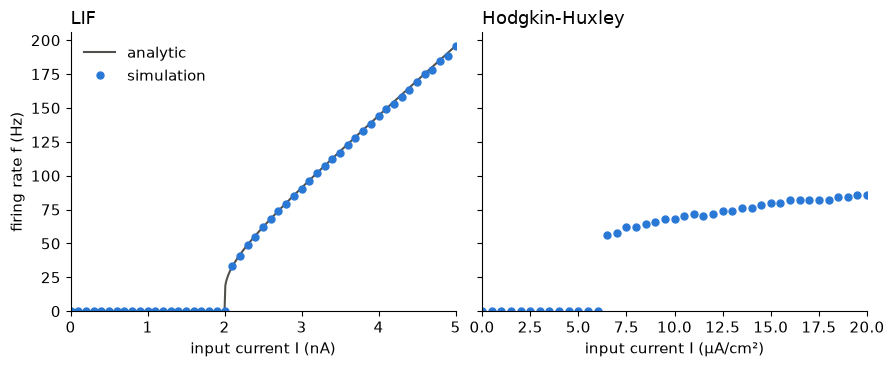

In [15]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 3.8), sharey=True)

ax1.plot(currents_fine, rates_theory, color=GRAY, lw=1.5, label="analytic")
ax1.plot(currents, rates_sim, "o", color=BLUE, ms=5, label="simulation")
ax1.set(xlim=(0, 5), ylim=(0, None), xlabel="input current I (nA)", ylabel="firing rate f (Hz)")
ax1.set_title("LIF", loc="left")
ax1.legend(frameon=False, loc="upper left")

ax2.plot(currents_hh, rates_hh, "o", color=BLUE, ms=5)
ax2.set(xlim=(0, 20), xlabel="input current I (µA/cm²)")
ax2.set_title("Hodgkin-Huxley", loc="left")

fig.tight_layout()
fig.savefig(FIG_DIR / "fI_lif_vs_hh.png", dpi=150)
plt.show()